# Esplorazio-analisia (EDA) · Praktika gidatua

**Datu-multzoa:** Iris (Fisher) — hiru lore-espezieren (*setosa*, *versicolor*, *virginica*) sepaloen eta petaloen neurriak (cm).

> ⚠️ Helburu didaktikoz, datuak **nahita hondatuta** daude (`iris_datuak.csv`): falta diren balioak, balio atipiko bat, errenkada bikoiztuak eta etiketa-akatsak dituzte. Zure lana: akatsak detektatu, erabakiak hartu eta datuak ulertu.

## Nola lan egin
- Exekutatu zelulak ordenan (`Shift + Enter`).
- 📘 **Teoria-pilula**: kontzeptu labur bat, hurrengo kodea ulertzeko.
- 🧪 **Ariketa**: zuk egin behar duzu. Pistak emanda daude.
- `iris_datuak.csv` fitxategia koadernoaren karpeta berean egon behar da.

## Helburuak
1. Datu-multzo baten egitura eta aldagai motak identifikatzea.
2. Datuen kalitatea aztertzea: falta diren balioak, bikoiztuak eta balio atipikoak.
3. Aldagaiak banaka, bikoteka eta multzo gisa bistaratzea (`matplotlib` + `seaborn`).
4. Datuetan oinarritutako ondorioak idaztea.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Aldagai numerikoen (feature) zerrenda, geroago erabiliko dugu
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

## 1. Datuak kargatu eta lehen begirada

In [2]:
df = pd.read_csv("iris_datuak.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.6,3.0,4.1,1.3,versicolor
1,7.2,3.2,6.0,1.8,virginica
2,4.8,3.0,1.4,0.3,setosa
3,4.8,3.4,1.6,0.2,setosa
4,6.9,3.1,4.9,1.5,versicolor


### 📘 Teoria-pilula 1 · Data Frame-aren hiztegia
- **DataFrame**: datu laukizuzenak (kalkulu-orri baten antzekoak). `pandas`-en oinarrizko egitura da.
- **Record** (errenkada): behaketa bakoitza. Hemen, lore bat.
- **Feature** (zutabea): neurtutako atributu bakoitza.
- **Outcome** (target): iragarri nahi dugun aldagaia. Hemen, `species`.

### 🧪 Ariketa 1
Zenbat record eta zenbat zutabe ditu `df`-k? Zein da outcome-a eta zeintzuk dira feature-ak?

In [3]:
print("Forma (record, zutabe):", df.shape)
print("Feature-ak:", features)
print("Outcome:", "species")

Forma (record, zutabe): (152, 5)
Feature-ak: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Outcome: species


✍️ **Zure erantzuna:** `df`-k **152 record** eta **5 zutabe** ditu. **Outcome-a** `species` da (iragarri nahi duguna) eta **feature-ak** lau neurketa numerikoak dira: `sepal_length`, `sepal_width`, `petal_length` eta `petal_width`. Kontuz: 152 record dira, ez 150 (Iris klasikoan 150 daude), hau da, bikoiztuak sartu dira.

## 2. Egitura eta aldagai motak

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  151 non-null    float64
 1   sepal_width   149 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   152 non-null    float64
 4   species       152 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.1 KB


In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,151.000000,149.000000,150.000000,152.000000
mean,6.173510,3.059732,3.748667,1.191447
std,4.324977,0.445688,1.762919,0.761659
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.400000,5.100000,1.800000
max,58.000000,4.400000,6.900000,2.500000


### 📘 Teoria-pilula 2 · Aldagai mota → grafiko mota
Grafiko egokia aukeratzeko, lehenengo galdetu: **zer motatako aldagaia da?**

| Aztertzen duguna | Grafiko egokiak | seaborn |
|---|---|---|
| Aldagai jarraitu bat | histograma, KDE, kutxa-diagrama | `histplot`, `kdeplot`, `boxplot` |
| Aldagai kategoriko bat | barra-diagrama | `countplot` |
| Jarraitua vs jarraitua | sakabanatze-diagrama (scatter) | `scatterplot` |
| Jarraitua vs kategorikoa | kutxa-diagrama, violin | `boxplot`, `violinplot` |
| Hainbat aldagai batera | pairplot, korrelazio-mapa | `pairplot`, `heatmap` |

In [6]:
df["species"].value_counts()

species
versicolor     48
virginica      48
setosa         47
Setosa          4
versicolor      3
VIRGINICA       2
Name: count, dtype: int64

### 🧪 Ariketa 2
a) Sailkatu bost zutabeak (jarraitua, diskretua, kategorikoa, bitarra edo ordinala).
b) `value_counts()`-en emaitza ikusita: **zer arazo ikusten duzu `species` zutabean?** Zenbat espezie daude benetan?

✍️ **a)**

| Zutabea | Mota |
|---|---|
| `sepal_length` | Jarraitua (cm-tan neurtutako zenbaki erreala) |
| `sepal_width` | Jarraitua |
| `petal_length` | Jarraitua |
| `petal_width` | Jarraitua |
| `species` | Kategorikoa (nominala: 3 espezie, ordenarik gabe) |

✍️ **b)** `value_counts()`-ek **6 kategoria** erakusten ditu, baina benetan **3 espezie** besterik ez daude. Arazoa **etiketen idazkera** da: `Setosa` / `setosa`, `VIRGINICA` / `virginica`... maiuskula/minuskula ezberdinak eta (seguruenik) zuriuneak. Pandas-ek kate bakoitza ezberdintzat hartzen du, beraz espezie bera hainbat kategoriatan zatitzen da. Konponbidea: `str.strip().str.lower()`.

## 3. Datuen kalitatea

### 3.1 Falta diren balioak

In [7]:
df.isna().sum()

sepal_length    1
sepal_width     3
petal_length    2
petal_width     0
species         0
dtype: int64

In [8]:
# Ehunekoa zutabe bakoitzeko
(df.isna().mean() * 100).round(1)

sepal_length    0.7
sepal_width     2.0
petal_length    1.3
petal_width     0.0
species         0.0
dtype: float64

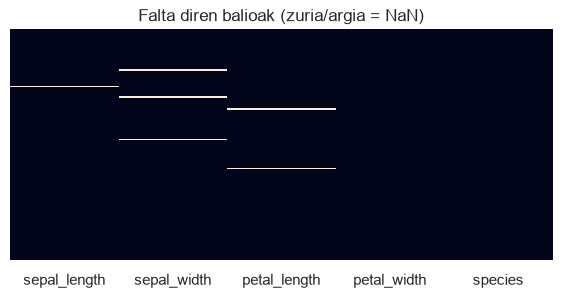

In [9]:
plt.figure(figsize=(7, 3))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Falta diren balioak (zuria/argia = NaN)")
plt.show()

### 🧪 Ariketa 3
Erakutsi balio falta duten errenkadak bakarrik.

In [10]:
df[df.isna().any(axis=1)]

,sepal_length,sepal_width,petal_length,petal_width,species
26,5.9,NaN,4.8,1.8,versicolor
37,NaN,3.2,5.7,2.3,virginica
44,6.1,NaN,5.6,1.4,virginica
52,4.6,3.1,NaN,0.2,Setosa
72,5.7,NaN,3.5,1.0,versicolor
91,6.3,2.7,NaN,1.8,virginica


### 3.2 Errenkada bikoiztuak

In [11]:
print("Bikoiztuak:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values(list(df.columns))

Bikoiztuak: 2


,sepal_length,sepal_width,petal_length,petal_width,species
13,5.0,2.0,3.5,1.0,versicolor
22,5.0,2.0,3.5,1.0,versicolor
105,5.4,3.7,1.5,0.2,setosa
118,5.4,3.7,1.5,0.2,setosa


### 3.3 Balio atipikoak (outlier-ak)

### 📘 Teoria-pilula 3 · Kutxa-diagrama (boxplot) irakurtzen
- **Kutxa**: Q1-etik Q3-ra (datuen % 50 erdikoa). Bere zabalera **IQR = Q3 − Q1** da.
- **Barruko marra**: mediana.
- **Bibotea**: Q1 − 1,5·IQR eta Q3 + 1,5·IQR artean dagoen azken balioa.
- **Kanpoko puntuak**: balio atipiko ahalmendunak.

⚠️ Atipikoa ez da beti akatsa. Erabaki aurretik, galdetu: *neurketa-akatsa da, ala aldakortasun naturala?*

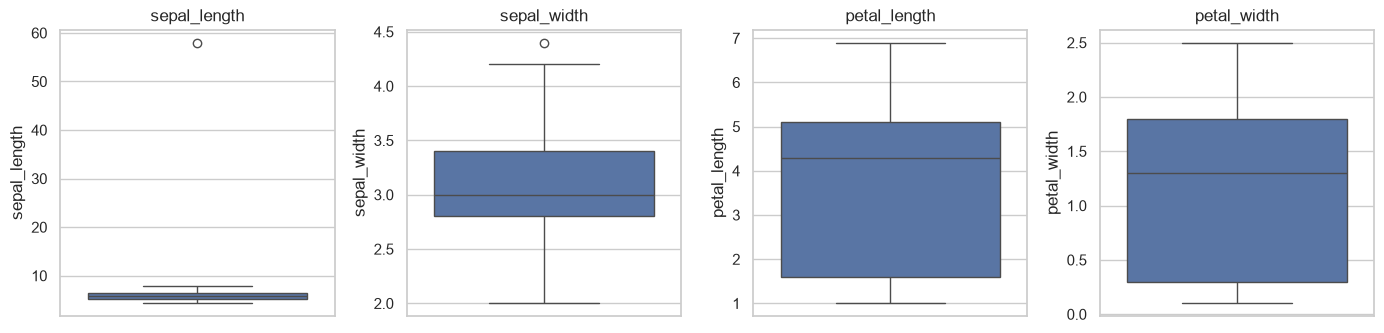

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
fig.tight_layout()
plt.show()

### 🧪 Ariketa 4
Idatzi `iqr_outliers(serie)` funtzioa, IQR araua aplikatzen duena (Q1 − 1,5·IQR azpitik edo Q3 + 1,5·IQR gainetik), eta aplikatu lau feature-ei.

In [13]:
def iqr_outliers(serie):
    """Itzultzen ditu IQR arauaren arabera (Q1-1.5*IQR, Q3+1.5*IQR) kanpoko balioak."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    behe, goi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return serie[(serie < behe) | (serie > goi)]

for col in features:
    atipikoak = iqr_outliers(df[col])
    print(f"{col:14s} -> {len(atipikoak)} atipiko: {atipikoak.tolist()}")

sepal_length   -> 1 atipiko: [58.0]
sepal_width    -> 1 atipiko: [4.4]
petal_length   -> 0 atipiko: []
petal_width    -> 0 atipiko: []


✍️ **Eztabaidatu:**

- **`sepal_length` = 58 cm**: **akatsa** da. Lore baten sepaloak ezin du 58 cm neurtu (gainerako balioak 4,3–7,9 cm artean daude); seguruenik komaren akatsa da (5,8). Gainera, batezbestekoa 6,17 cm-ra eta desbiderazioa 4,32-ra puzten ditu.
- **`sepal_width` = 4,4 cm**: **ez da akatsa**, aldakortasun naturala baizik. Balio fisikoki erabat posiblea da (setosa espezieko lore zabalenen artean dago) eta gainerako datuekin bat dator. IQR arauak "atipiko" gisa markatzen du, baina atipiko estatistikoa ≠ akatsa. Beraz, mantendu egiten dugu.

### 3.4 Garbiketa

### 📘 Teoria-pilula 4 · Garbiketa-erabakiak
Akats bakoitzarentzat erabaki bat hartu behar da, eta **ordena garrantzitsua da**:

1. **Etiketak normalizatu** (`str.strip().str.lower()`), bestela bikoiztuak ez dira detektatzen.
2. **Bikoiztuak ezabatu** (`drop_duplicates`).
3. **Akatsa den atipikoa**: ezabatu, zuzendu (58 → 5,8?) edo `NaN` bihurtu. Guk `NaN` bihurtuko dugu, ziur ez gaudelako zein den benetako balioa.
4. **Falta diren balioak imputatu**: hemen espezie bakoitzaren medianarekin (mediana ez da atipikoekiko sentikorra).

In [14]:
df_clean = df.copy()

# 1) Etiketak
df_clean["species"] = df_clean["species"].str.strip().str.lower()

# 2) Bikoiztuak
df_clean = df_clean.drop_duplicates()

# 3) Akatsa den atipikoa -> NaN (58 cm ezinezkoa da)
df_clean.loc[df_clean["sepal_length"] > 20, "sepal_length"] = np.nan

# 4) Imputazioa: espezie bakoitzaren mediana
for col in features:
    df_clean[col] = df_clean.groupby("species")[col].transform(lambda s: s.fillna(s.median()))

df_clean = df_clean.reset_index(drop=True)

print("Forma:", df_clean.shape)
print("NaN guztira:", df_clean.isna().sum().sum())
df_clean["species"].value_counts()

Forma: (150, 5)
NaN guztira: 0


species
versicolor    50
virginica     50
setosa        50
Name: count, dtype: int64

### 🧪 Ariketa 5
Alderatu `sepal_length`-en estatistikoak garbiketa aurretik eta ondoren (`describe()`). Zer aldatu da gehien?

In [15]:
pd.concat([df["sepal_length"].describe(), df_clean["sepal_length"].describe()],
          axis=1, keys=["aurretik", "ondoren"]).round(2)

,aurretik,ondoren
count,151.00,150.00
mean,6.17,5.85
std,4.32,0.83
min,4.30,4.30
25%,5.10,5.10
50%,5.80,5.80
75%,6.40,6.40
max,58.00,7.90


✍️ **Zure erantzuna:** Gehien aldatu dena **maximoa** (58 → 7,9) eta **desbiderazio estandarra** (4,32 → 0,83) dira, baita **batezbestekoa** ere (6,17 → 5,85). Mediana, Q1 eta Q3 ia ez dira mugitu (5,8 / 5,1 / 6,4): **mediana sendoa da atipikoekiko**, batezbestekoa eta desbiderazioa, ordea, oso sentikorrak. Count-a ere aldatu da (151 → 150): bikoiztuak kendu eta falta ziren balioak imputatu ditugu.

## 4. Analisi unibariatua: aldagai bakoitza bere aldetik

### 📘 Teoria-pilula 5 · matplotlib eta seaborn: nola elkartzen diren
- `matplotlib` oinarria da. Bi kontzeptu: **Figure** (orri osoa) eta **Axes** (orriko grafiko bakoitza).
- `seaborn` matplotlib-en gainean dago eta DataFrame-ekin zuzenean lan egiten du: `sns.histplot(data=df, x="zutabea")`.
- Bi funtzio-familia:
  - **Axes-level** (`histplot`, `boxplot`, `scatterplot`, `countplot`, `heatmap`...): Axes bakar batean marrazten dute. `ax=` parametroarekin aukeratzen da non.
  - **Figure-level** (`pairplot`, `displot`, `catplot`, `relplot`): Figure osoa sortzen dute eta ez dute `ax=` onartzen.
- Eredu ohikoena: `fig, ax = plt.subplots()` → seaborn-ekin marraztu `ax=ax`-rekin → `ax.set_title(...)` bidez pertsonalizatu.

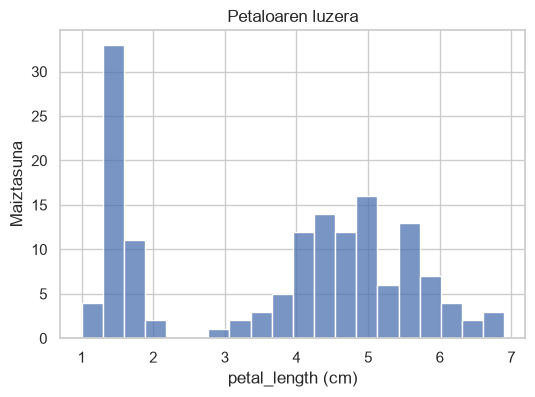

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df_clean, x="petal_length", bins=20, ax=ax)
ax.set_title("Petaloaren luzera")
ax.set_xlabel("petal_length (cm)")
ax.set_ylabel("Maiztasuna")
plt.show()

### 📘 Teoria-pilula 6 · Histograma eta KDE
Histogramak balioak tarteetan (*bin*) banatzen ditu. Bin gutxiegi → informazioa galtzen da; gehiegi → zarata. **KDE** histogramaren bertsio leuna da (dentsitate-estimazioa): `kde=True`.

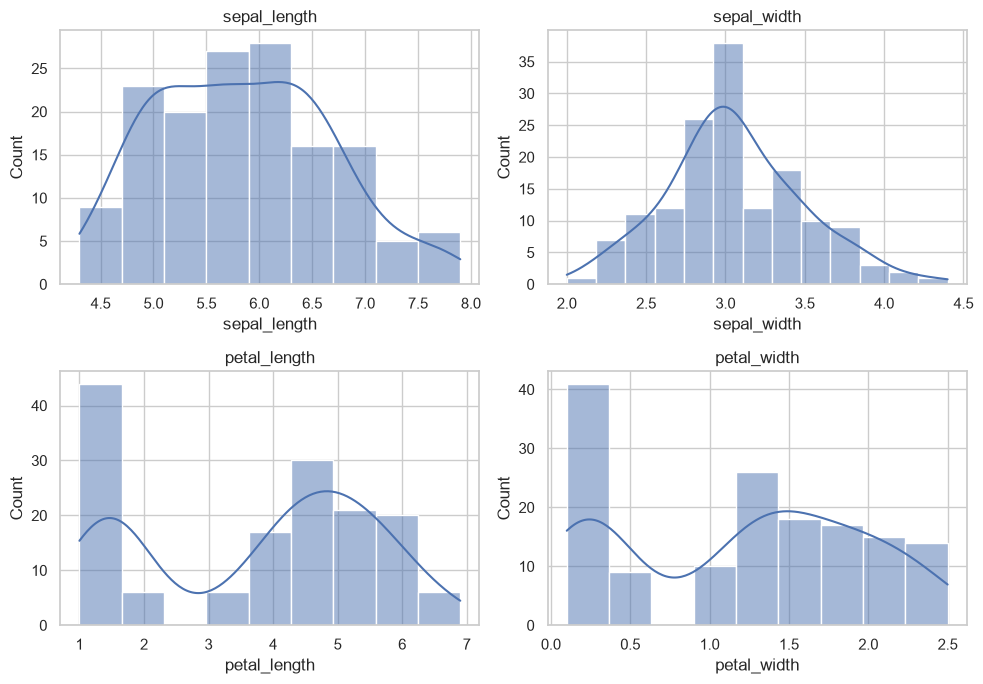

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, features):
    sns.histplot(data=df_clean, x=col, kde=True, ax=ax)
    ax.set_title(col)
fig.tight_layout()
plt.show()

### 🧪 Ariketa 6
Egin bi grafiko elkarren ondoan: (a) `petal_length`-en histograma, espezie bakoitza kolore batekin (`hue`); (b) espezie bakoitzeko record kopurua (`countplot`). Zein espezie bereizten da errazen?

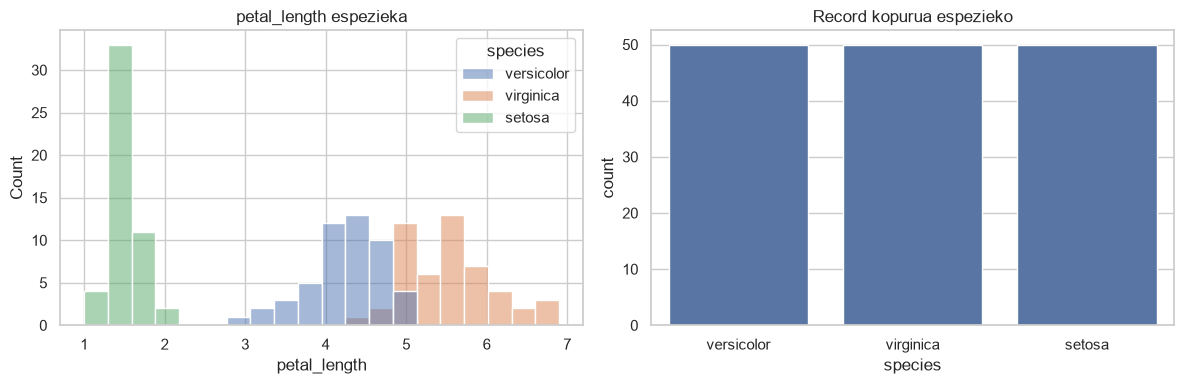

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_clean, x="petal_length", hue="species", bins=20, ax=axes[0])
axes[0].set_title("petal_length espezieka")
sns.countplot(data=df_clean, x="species", ax=axes[1])
axes[1].set_title("Record kopurua espezieko")
fig.tight_layout()
plt.show()

✍️ **Zure erantzuna:** **Setosa** da errazen bereizten dena: bere petaloen luzera (1–1,9 cm) beste bi espezieenekin (3–6,9 cm) ez da gainjartzen. Versicolor eta virginica pixka bat gainjartzen dira 4,5–5,1 cm inguruan. Countplot-ak erakusten du garbiketa ondoren **50 record espezie bakoitzeko** daudela: datu-multzo orekatua da.

### 🧪 Ariketa 7
Aldatu grafiko mota: marraztu `sepal_width`-en kutxa-diagrama (`boxplot`) eta violin-diagrama (`violinplot`) espezieka. Zer informazio gehiago ematen du violin-ak?

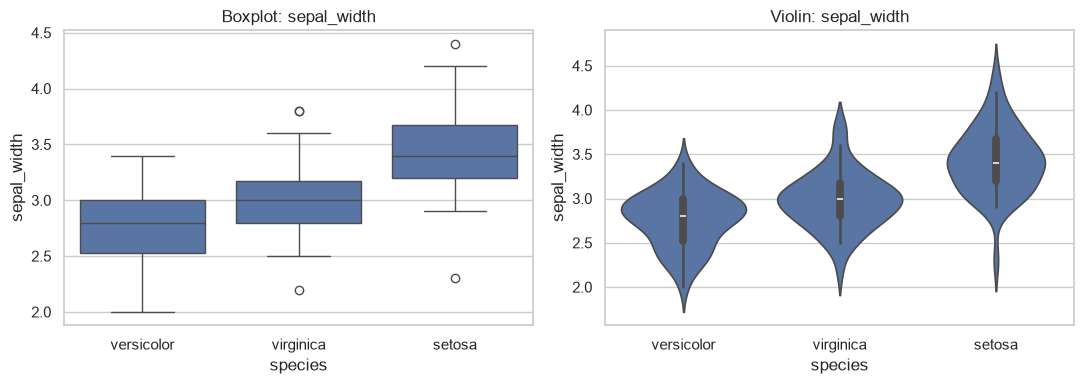

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df_clean, x="species", y="sepal_width", ax=axes[0])
axes[0].set_title("Boxplot: sepal_width")
sns.violinplot(data=df_clean, x="species", y="sepal_width", ax=axes[1])
axes[1].set_title("Violin: sepal_width")
fig.tight_layout()
plt.show()

✍️ **Zure erantzuna:** Boxplot-ak bost zenbaki-laburpena (mediana, kuartilak, bibotea eta atipikoak) ematen du bakarrik. **Violin-ak banaketaren forma osoa** erakusten du (dentsitatea): simetria edo asimetria, gailur bat edo gehiago dauden, eta non pilatzen diren datuak. Gainera, kutxa-diagrama bera barruan sartzen du. Sepal-zabalerari dagokionez, setosa nabarmen zabalagoa da (mediana ~3,4 cm) eta versicolor estuena (~2,8 cm).

## 5. Analisi bibariatua: bi aldagairen arteko erlazioa

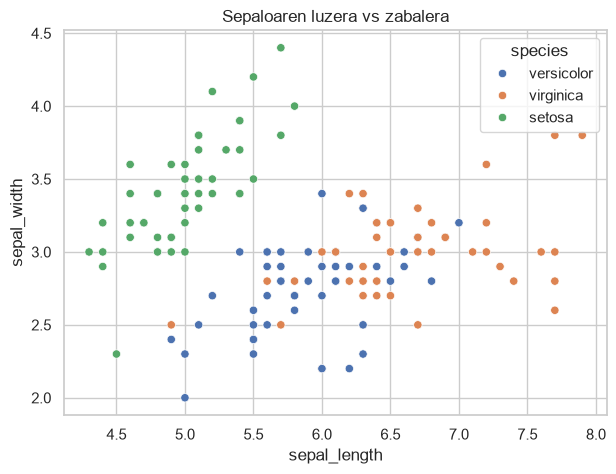

In [20]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="sepal_length", y="sepal_width", hue="species")
plt.title("Sepaloaren luzera vs zabalera")
plt.show()

### 📘 Teoria-pilula 7 · Grafikoa pertsonalizatu
- Dimentsio gehiago gehitu: `hue` (kolorea), `style` (marka-forma), `size` (tamaina).
- `palette="Set2"` bidez kolore-paleta aldatu.
- Testuak: `plt.title()`, `plt.xlabel()`, `plt.ylabel()` (edo `ax.set_title()`...).
- Gorde: `plt.savefig("grafikoa.png", dpi=150, bbox_inches="tight")` (deitu `plt.show()` baino **lehen**).

### 🧪 Ariketa 8
Marraztu `petal_length` vs `petal_width` scatter bat, espezieka koloreztatuta, `style="species"` gehituta. **Zein aldagai-parek bereizten ditu hobeto espezieak**: sepaloenak ala petaloenak?

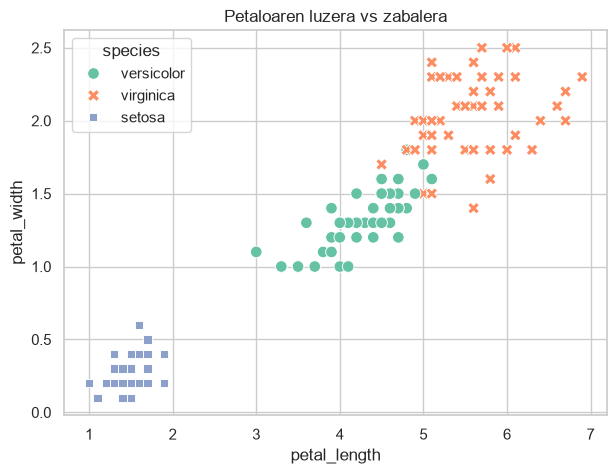

In [21]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="petal_length", y="petal_width",
                hue="species", style="species", palette="Set2", s=70)
plt.title("Petaloaren luzera vs zabalera")
plt.show()

✍️ **Zure erantzuna:** **Petaloen neurriek** bereizten dituzte hobeto espezieak. `petal_length` vs `petal_width` grafikoan hiru taldeak ondo bereizita agertzen dira (setosa guztiz isolatuta, versicolor eta virginica gainjartze oso txikiarekin). Sepaloen grafikoan, aldiz, versicolor eta virginica nahastuta daude eta bereizketa askoz okerragoa da.

## 6. Analisi multibariatua: dena batera

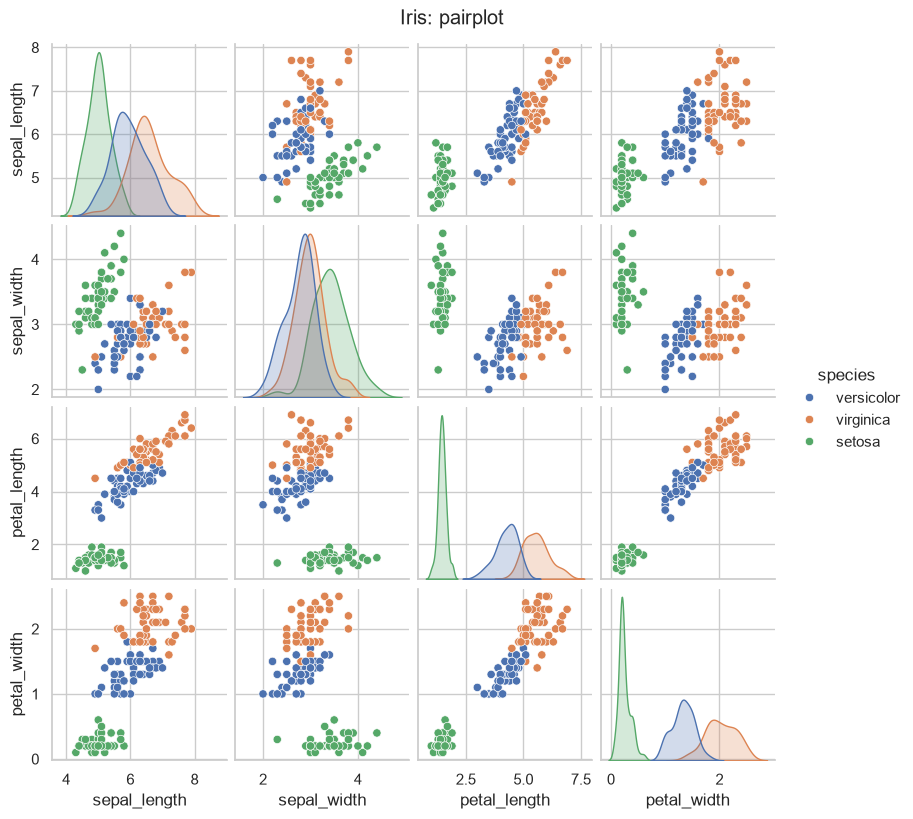

In [22]:
g = sns.pairplot(df_clean, hue="species", height=2)
g.figure.suptitle("Iris: pairplot", y=1.02)
plt.show()

### 🧪 Ariketa 9
Pairplot-a interpretatu (idatzi 3-4 ondorio):
- Zer erakusten dute **diagonaleko** grafikoek?
- Zein aldagai-pare dute gainjartze txikiena?
- Zein espezie da errazena bereizteko? Zein bikote nahasten dira?

✍️ **Zure erantzuna:**
- **Diagonala**: aldagai bakoitzaren banaketa espezieka (KDE). Setosa-ren kurba petaloen aldagaietan gainerakoetatik oso urrun dago; versicolor eta virginica-ren kurbak gertuago eta pixka bat gainjarrita daude.
- **Gainjartze txikiena**: `petal_length` eta `petal_width` bikotea (eta petaloen aldagaiak orokorrean). Taldeak ia erabat bereizita geratzen dira.
- **Espezie errazena**: **setosa**, aldagai guztietan ia, batez ere petaloetan.
- **Nahasten direnak**: **versicolor eta virginica**, bereziki sepaloen neurrietan (`sepal_length` vs `sepal_width`). Petaloetan bakarrik gainjartze txiki bat geratzen da.
- Gainera, `petal_length` eta `petal_width` oso lotuta daude (erlazio lineal sendoa).

### 📘 Teoria-pilula 8 · Korrelazioa
- **Pearson-en r**: −1 (alderantzizko erlazio lineal perfektua) eta +1 (zuzena) artean. 0 inguruan, erlazio linealik ez.
- `df.corr()` matrizea kalkulatzen du; `sns.heatmap(..., annot=True)` bidez bistaratzen da.
- ⚠️ **Korrelazioa ≠ kausalitatea**, eta datu guztien korrelazioak talde bakoitzaren barruko erlazioa ezkutatu dezake.

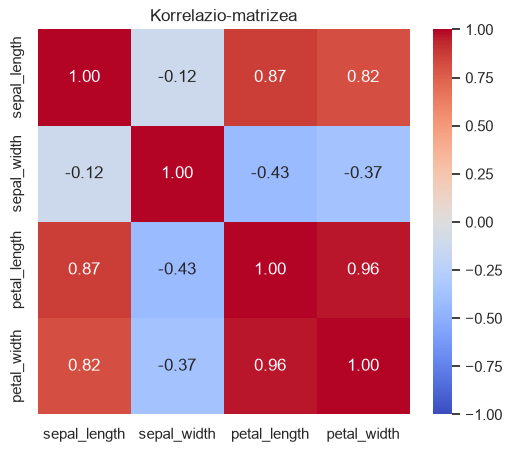

In [23]:
corr = df_clean[features].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korrelazio-matrizea")
plt.show()

### 🧪 Ariketa 10
`sepal_length` eta `sepal_width`-en arteko korrelazioa kalkulatu: (a) datu guztiekin, (b) espezie bakoitzaren barruan. Zer ikusten duzu?

In [24]:
print("(a) Datu guztiekin:", round(df_clean["sepal_length"].corr(df_clean["sepal_width"]), 3))
print("(b) Espezie bakoitzaren barruan:")
for sp, g in df_clean.groupby("species"):
    print(f"   {sp:11s} r = {g['sepal_length'].corr(g['sepal_width']):.3f}")

(a) Datu guztiekin: -0.123
(b) Espezie bakoitzaren barruan:
   setosa      r = 0.743
   versicolor  r = 0.534
   virginica   r = 0.423


✍️ **Zure erantzuna:** Datu guztiekin korrelazioa ia nulua eta ezkorra da (r ≈ −0,12), hau da, ez dirudi erlaziorik dagoenik. Baina espezie bakoitzaren barruan korrelazioa positibo eta nabarmena da (setosa r ≈ 0,74; versicolor ≈ 0,53; virginica ≈ 0,42). Hau Simpson-en paradoxaren antzeko efektua da: espezieen arteko diferentziek (setosa-k sepalo labur baina zabalak ditu) talde barruko joera positiboa ezkutatzen dute. Ondorioa: datu osoen korrelazioak ez du talde bakoitzaren erlazioa erakusten.

## 7. Ondorioak eta erronka

### EDA kontrol-zerrenda
1. Egitura: zenbat record, zein feature, zein outcome, zein motatako aldagaiak?
2. Kalitatea: falta diren balioak, bikoiztuak, balio atipikoak, etiketa-akatsak.
3. Banaka: banaketak, asimetriak, atipikoak.
4. Bikoteka eta multzo gisa: erlazioak, korrelazioak, taldeen bereizgarritasuna.
5. Ondorioak eta hurrengo urratsa (ereduak, ezaugarrien aukeraketa...).

### 📘 Txuleta
| Zer nahi dut | Kodea |
|---|---|
| Banaketa | `sns.histplot(data=df, x="col", kde=True)` |
| Taldeak alderatu | `sns.boxplot(data=df, x="taldea", y="col")` |
| Kategoria kopurua | `sns.countplot(data=df, x="col")` |
| Bi aldagai | `sns.scatterplot(data=df, x="a", y="b", hue="taldea")` |
| Dena batera | `sns.pairplot(df, hue="taldea")` |
| Korrelazioak | `sns.heatmap(df.corr(numeric_only=True), annot=True)` |

### 🏁 Erronka final: pinguinoak
`penguins.csv` datu-multzoarekin (Palmer Station, Antartika), egin zure EDA osoa:
1. Kargatu eta deskribatu egitura (zein dira feature-ak eta zein kategorikoak?).
2. Aztertu datuen kalitatea (falta diren balioak batez ere) eta erabaki zer egin.
3. Egin gutxienez **3 grafiko** desberdin (bat unibariatua, bat bibariatua eta bat multibariatua).
4. Idatzi **5 lerroko ondorioak**: zein espeziek dituzte neurri desberdinak? Zein aldagaik bereizten dituzte hobeto?

In [25]:
penguins = pd.read_csv("penguins.csv")
penguins.head()

# Zure EDA hemen (gehitu behar adina zelula)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [26]:
print("Forma:", penguins.shape)
penguins.info()

Forma: (344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [27]:
penguins.describe().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


In [28]:
print(penguins.isna().sum())
print("Bikoiztuak:", penguins.duplicated().sum())
penguins[penguins.isna().any(axis=1)]

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Bikoiztuak: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


In [29]:
p = penguins.dropna(subset=["bill_length_mm"]).copy()
p["sex"] = p["sex"].fillna("Ezezaguna")
num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print("Forma garbiketa ondoren:", p.shape)
print("NaN guztira:", p.isna().sum().sum())
p["species"].value_counts()

Forma garbiketa ondoren: (342, 7)
NaN guztira: 0


species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

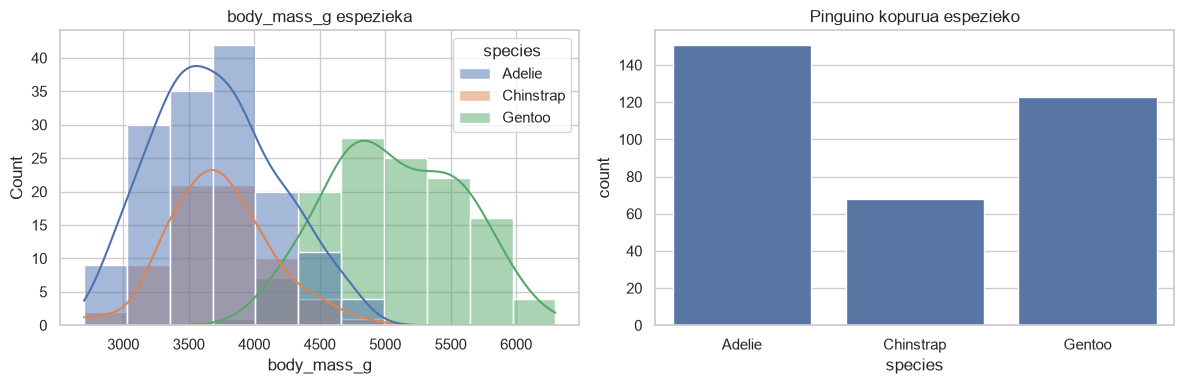

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=p, x="body_mass_g", hue="species", kde=True, ax=axes[0])
axes[0].set_title("body_mass_g espezieka")
sns.countplot(data=p, x="species", ax=axes[1])
axes[1].set_title("Pinguino kopurua espezieko")
fig.tight_layout()
plt.show()

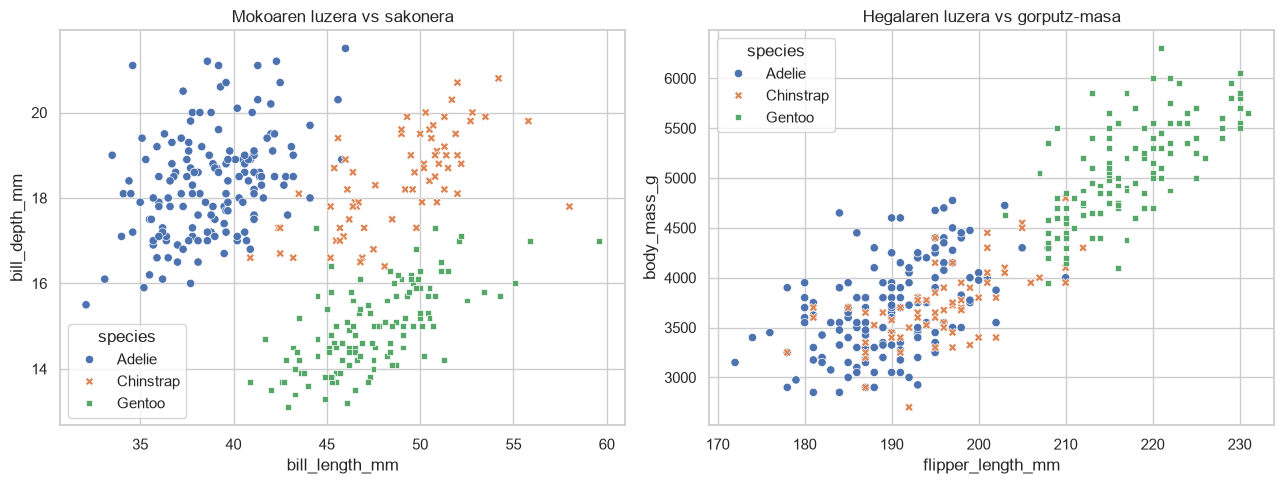

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=p, x="bill_length_mm", y="bill_depth_mm", hue="species", style="species", ax=axes[0])
axes[0].set_title("Mokoaren luzera vs sakonera")
sns.scatterplot(data=p, x="flipper_length_mm", y="body_mass_g", hue="species", style="species", ax=axes[1])
axes[1].set_title("Hegalaren luzera vs gorputz-masa")
fig.tight_layout()
plt.show()

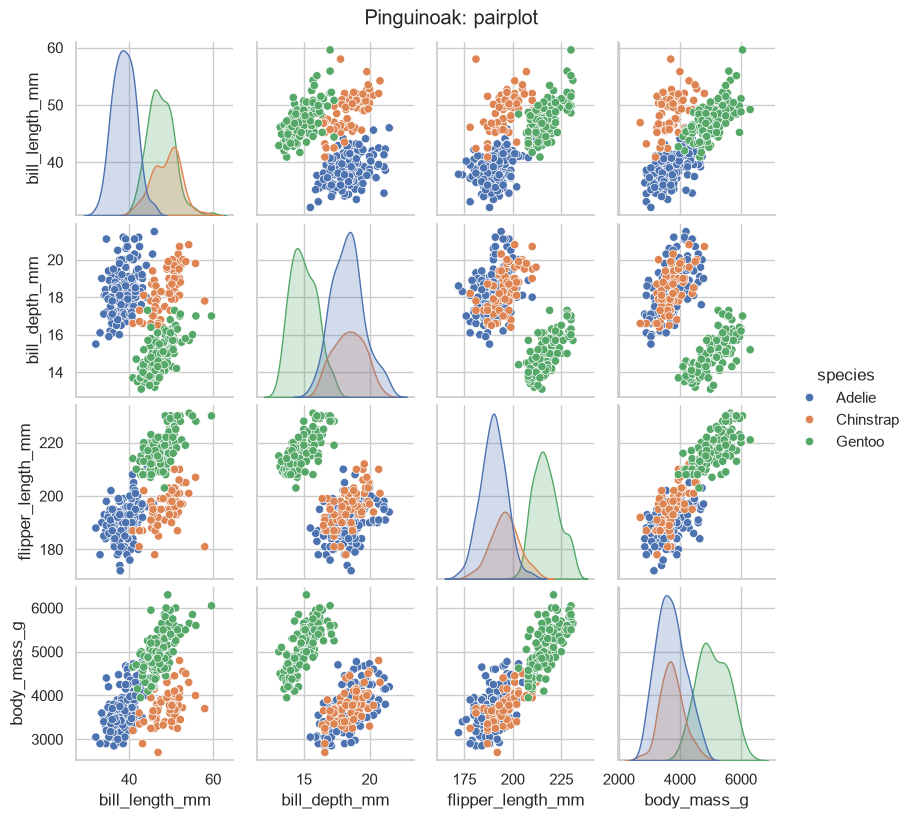

In [32]:
g = sns.pairplot(p[num + ["species"]], hue="species", height=2)
g.figure.suptitle("Pinguinoak: pairplot", y=1.02)
plt.show()

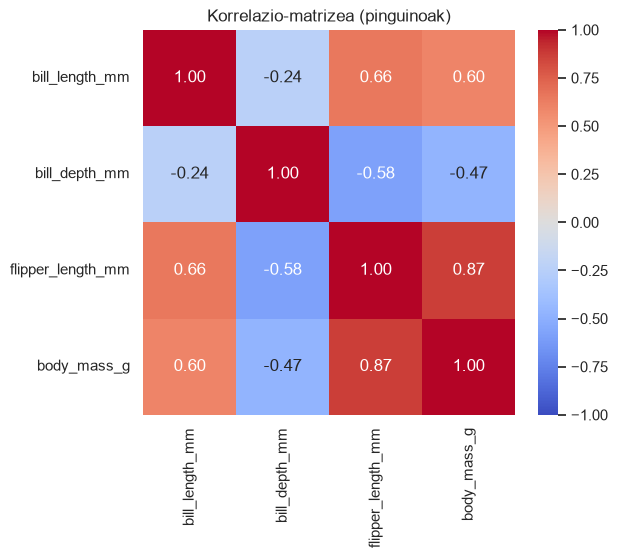

In [33]:
plt.figure(figsize=(6, 5))
sns.heatmap(p[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korrelazio-matrizea (pinguinoak)")
plt.show()

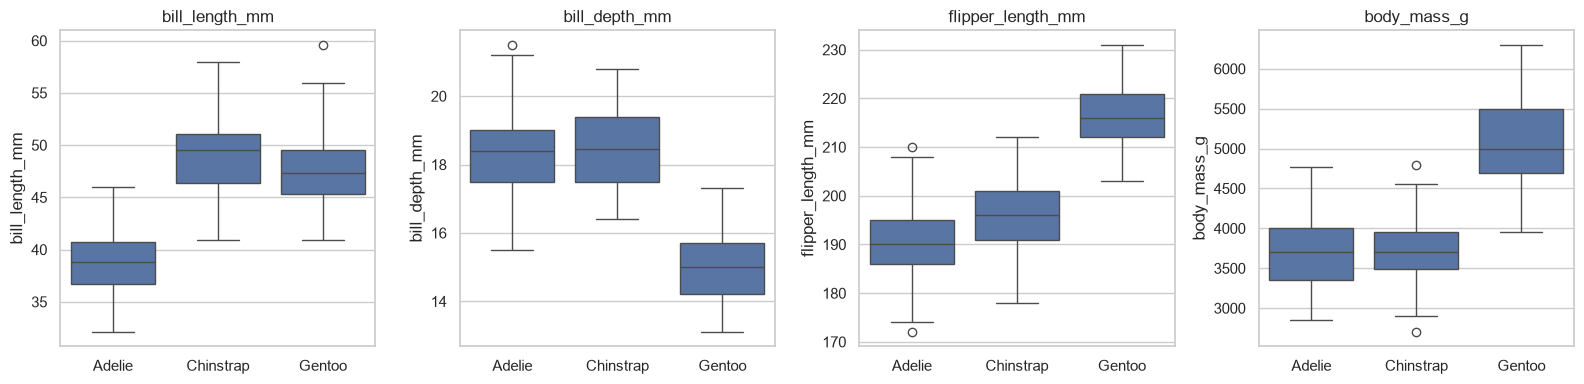

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


In [34]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num):
    sns.boxplot(data=p, x="species", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.tight_layout()
plt.show()
p.groupby("species")[num].mean().round(1)

In [35]:
# Simpson-en efektua: sakonera vs luzera, datu guztiekin eta espezieka
print("Datu guztiekin r =", round(p["bill_length_mm"].corr(p["bill_depth_mm"]), 2))
for sp, g in p.groupby("species"):
    print(f"{sp:10s} r = {g['bill_length_mm'].corr(g['bill_depth_mm']):.2f}")

Datu guztiekin r = -0.24
Adelie     r = 0.39
Chinstrap  r = 0.65
Gentoo     r = 0.64


#### 4. Ondorioak 


1. **Gentoo** espeziea argi bereizten da: **handiena** (batez beste ~5.076 g eta ~217 mm-ko hegalak) eta **moko sakonera txikiena** (~15,0 mm). Hegal-luzera eta masa dira Gentoo identifikatzeko aldagairik onenak.
2. **Adelie eta Chinstrap** gorputz-masan eta hegal-luzeran antzekoak dira (~3.700 g; 190 vs 196 mm), baina **moko-luzeran** argi bereizten dira: Adelie ~38,8 mm eta Chinstrap ~48,8 mm.
3. **`bill_length_mm`-k** Adelie-ri Chinstrap/Gentoo-tik bereizten dio, eta **`flipper_length_mm`/`body_mass_g`-k** Gentoo-ri gainerakoengandik. **Bi aldagai konbinatuta** (luzera + sakonera, edo hegala + moko-luzera) hiru espezieak ia guztiz bereizten dira.
4. Korrelazioak: `flipper_length_mm` eta `body_mass_g` oso lotuta daude (r ≈ 0,87). **Simpson-en paradoxa** ere agertzen da: moko-luzera eta -sakonera datu guztiekin **ezkor** erlazionatuta daude (r ≈ −0,24), baina espezie bakoitzaren barruan **positiboki** (r ≈ 0,39–0,65).
5. Datuen kalitatea ona da: 2 errenkada hutsik kendu ditugu eta 9 pinguinoren sexua ezezagun gisa markatu dugu. Hurrengo urratsa: sailkapen-eredu bat (adibidez zuhaitz erabakia edo k-NN) lau neurri hauekin espeziea iragartzeko.